In [122]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import warnings 
warnings.filterwarnings("ignore")
#from xgboost import XGBRegressor

In [123]:
df=pd.read_csv("D:\Student_Performance.csv")

In [124]:
df.head(10)

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0
5,3,78,No,9,6,61.0
6,7,73,Yes,5,6,63.0
7,8,45,Yes,4,6,42.0
8,5,77,No,8,2,61.0
9,4,89,No,4,0,69.0


In [125]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [126]:
df.tail()


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
9995,1,49,Yes,4,2,23.0
9996,7,64,Yes,8,5,58.0
9997,6,83,Yes,8,5,74.0
9998,9,97,Yes,7,0,95.0
9999,7,74,No,8,1,64.0


In [127]:
df.isna().sum()

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

In [128]:
x=df.drop("Performance Index",axis=1)
y=df["Performance Index"]

In [129]:
for i in x.columns:
    print(i,x[i].unique())

Hours Studied [7 4 8 5 3 6 2 1 9]
Previous Scores [99 82 51 52 75 78 73 45 77 89 91 79 47 72 83 54 96 74 85 61 62 84 94 90
 44 70 67 97 59 55 68 63 46 76 43 81 93 98 48 92 64 88 60 87 40 69 80 95
 49 50 53 71 56 58 66 65 57 41 42 86]
Extracurricular Activities ['Yes' 'No']
Sleep Hours [9 4 7 5 8 6]
Sample Question Papers Practiced [1 2 5 6 0 8 3 4 9 7]


<Axes: xlabel='Hours Studied', ylabel='Performance Index'>

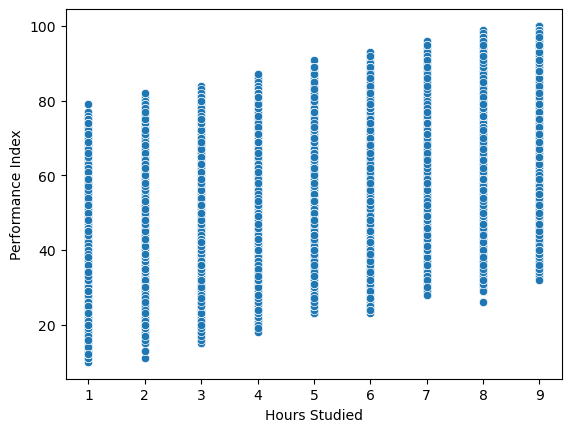

In [130]:
import seaborn as sns
sns.scatterplot(data=df,x="Hours Studied",y="Performance Index")

<Axes: xlabel='Hours Studied', ylabel='Performance Index'>

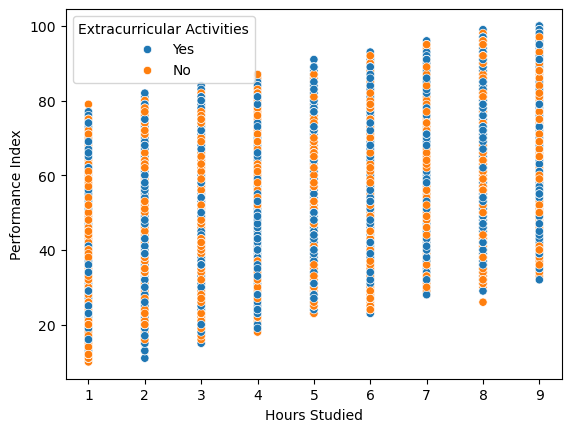

In [131]:
sns.scatterplot(data=df,x="Hours Studied",y="Performance Index",hue="Extracurricular Activities")

<Axes: ylabel='Extracurricular Activities'>

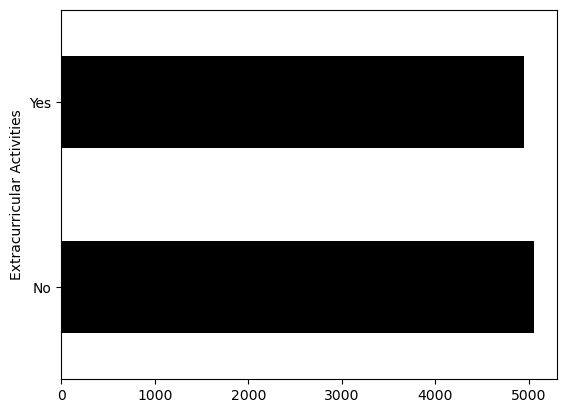

In [132]:
df["Extracurricular Activities"].value_counts().plot(kind="barh",color="black")

<Axes: xlabel='Sample Question Papers Practiced'>

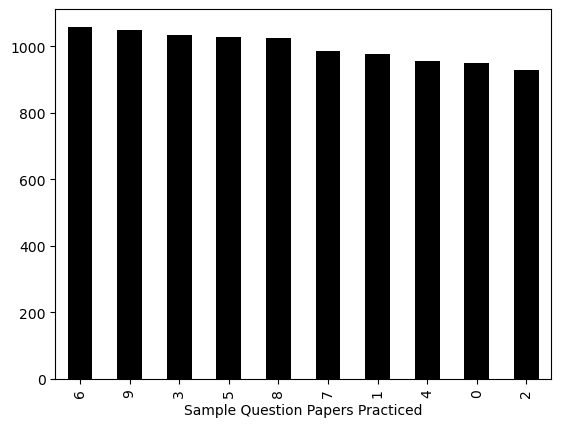

In [133]:
df["Sample Question Papers Practiced"].value_counts().plot(kind="bar",color="black")

<Axes: xlabel='Hours Studied'>

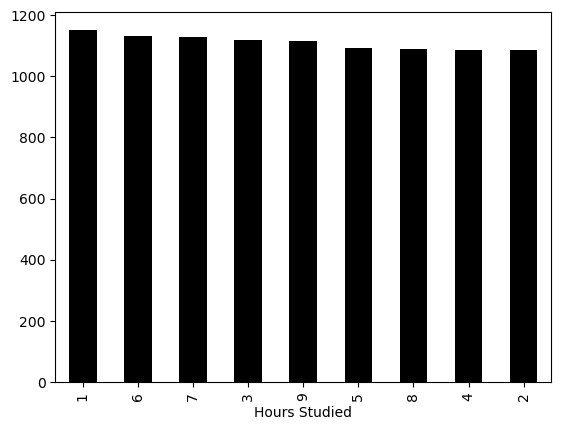

In [134]:
df["Hours Studied"].value_counts().plot(kind="bar",color="black")

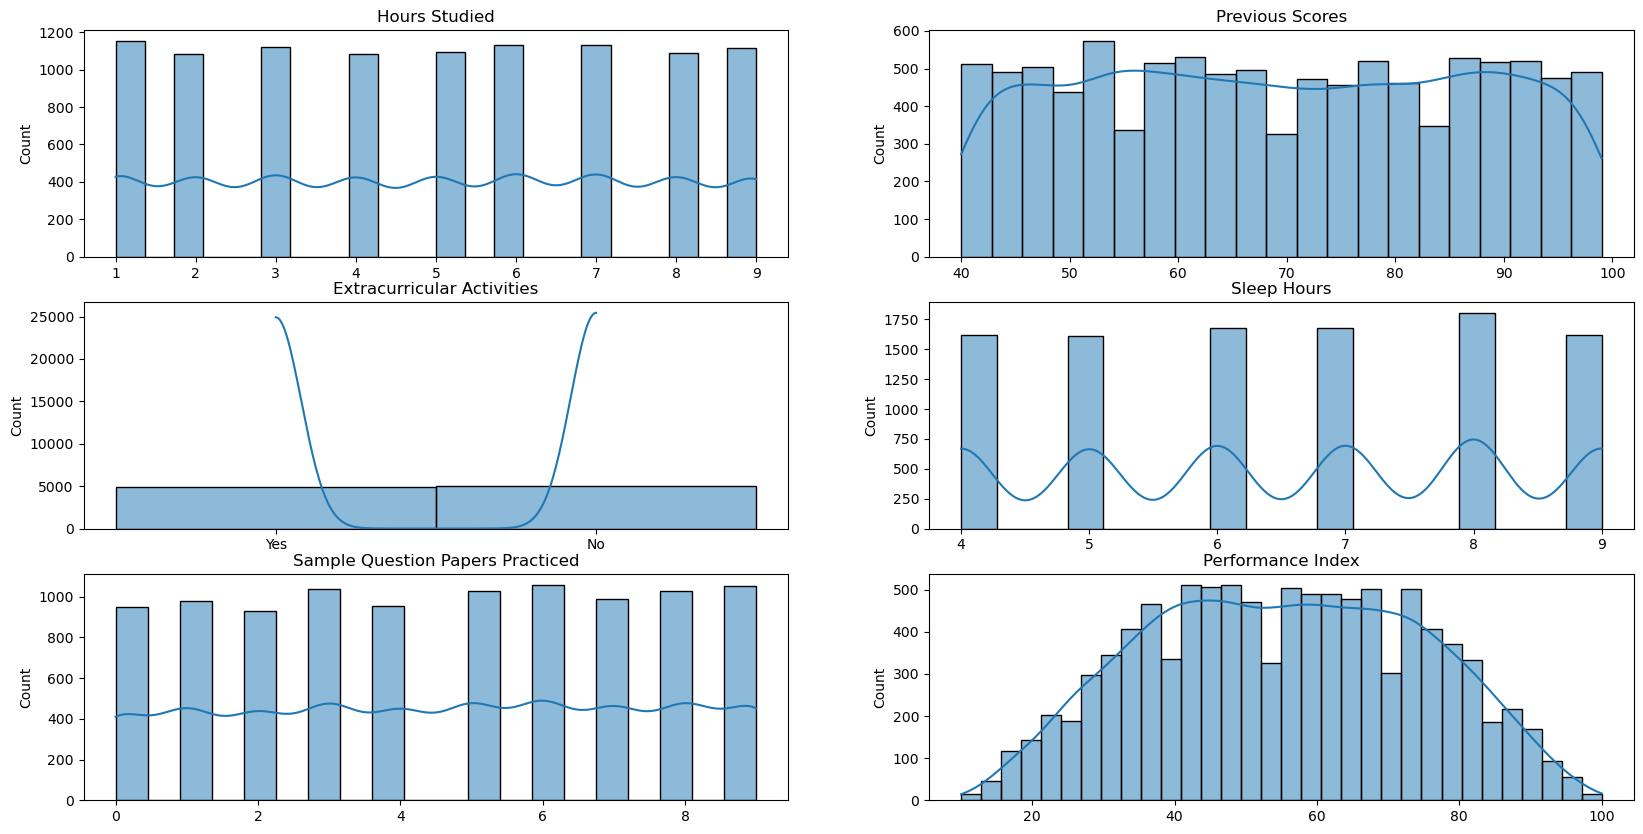

In [135]:
plt.figure(figsize=(20,10))
for i,col in enumerate(df.columns):
    plt.subplot(3,2,i+1)
    sns.histplot(df[col],kde=True)
    plt.xlabel("")
    plt.title(col)
  
plt.show()

In [136]:
df["Performance Index"].unique()

array([ 91.,  65.,  45.,  36.,  66.,  61.,  63.,  42.,  69.,  84.,  73.,
        27.,  33.,  68.,  43.,  67.,  70.,  30.,  71.,  85.,  57.,  35.,
        49.,  83.,  74.,  39.,  58.,  47.,  60.,  32.,  64.,  54.,  17.,
        53.,  75.,  52.,  78.,  38.,  98.,  87.,  41.,  81.,  15.,  88.,
        95.,  29.,  21.,  76.,  25.,  34.,  50.,  56.,  82.,  23.,  46.,
        92.,  77.,  86.,  44.,  94.,  40., 100.,  31.,  26.,  18.,  51.,
        72.,  16.,  28.,  89.,  48.,  37.,  62.,  59.,  19.,  79.,  22.,
        10.,  90.,  80.,  24.,  20.,  96.,  55.,  97.,  12.,  93.,  14.,
        99.,  11.,  13.])

In [140]:
models={
"LinearRegression":LinearRegression(),
"DecisionTreeRegressor":DecisionTreeRegressor(),
"RandomForestRegressor":RandomForestRegressor(),
"LogisticRegression":LogisticRegression()
}

In [154]:
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
X_train["Extracurricular Activities"]=X_train["Extracurricular Activities"].map({"Yes":1,"No":0})
X_test["Extracurricular Activities"]=X_test["Extracurricular Activities"].map({"Yes":1,"No":0})

In [161]:
for i in range(len(list(models))):
    model=list(models.values())[i]
    model.fit(X_train,y_train)
    y_train_pred=model.predict(X_train)
    y_test_pred=model.predict(X_test)
    print(list(models.keys())[i])
    print("*"*60)
    print(y_train_pred)
    print(y_test_pred)
    print("="*60)
    cal(y_train,y_train_pred)
    print("="*60)
    cal(y_test,y_test_pred)

LinearRegression
************************************************************
[34.47064278 25.69665091 57.88131903 ... 45.05542174 21.02145642
 22.57711635]
[54.71185392 22.61551294 47.90314471 ... 16.79341955 63.34327368
 45.94262301]
Mean Squared Error: 4.169735849525006
Mean Absolute Error: 1.6193054830334266
R2 Score: 0.9886898790682355
Mean Squared Error: 4.082628398521856
Mean Absolute Error: 1.6111213463123049
R2 Score: 0.9889832909573145
DecisionTreeRegressor
************************************************************
[36. 25. 59. ... 44. 20. 24.]
[55.  24.  45.  ... 18.  61.5 44. ]
Mean Squared Error: 0.256375
Mean Absolute Error: 0.13945833333333332
R2 Score: 0.9993046004930477
Mean Squared Error: 8.667805555555555
Mean Absolute Error: 2.3196666666666665
R2 Score: 0.9766104865486407
RandomForestRegressor
************************************************************
[35.27       24.79       58.93       ... 44.8        21.00666667
 23.05      ]
[56.188      21.84       46.28   

In [158]:
def cal(true,pred):
    print("Mean Squared Error:",mean_squared_error(true,pred))
    print("Mean Absolute Error:",mean_absolute_error(true,pred))
    print("R2 Score:",r2_score(true,pred))